In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

Please Upload An Image Containing Human Skin:


Saving LISA-HD-WALLPAPER-4K.jpg to LISA-HD-WALLPAPER-4K.jpg
Input Image: LISA-HD-WALLPAPER-4K.jpg
Image Shape: (1307, 736, 3)


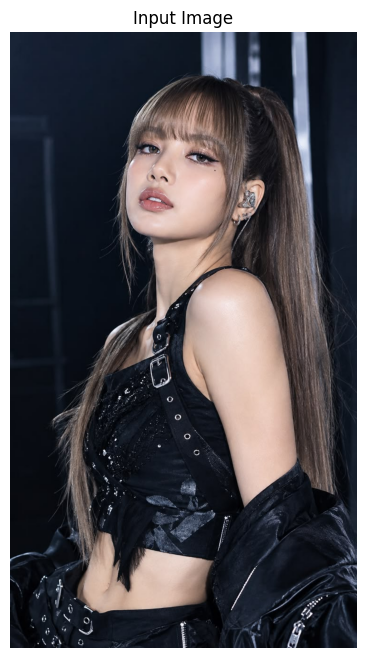

In [2]:
print("Please Upload An Image Containing Human Skin:")
uploaded = files.upload()

if len(uploaded) == 0:
  raise Exception("No File Uploaded")

image_name = list(uploaded.keys())[0]
image_path = '/content/' + image_name

img = cv2.imread(image_path)

if img is None:
  raise Exception("Image Not Found")

print('Input Image:', image_name)
print('Image Shape:', img.shape)

plt.figure(figsize=(10, 8))

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Input Image')
plt.axis('off')

plt.show()

In [3]:
B, G, R = cv2.split(img)

img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
H, S, V = cv2.split(img_hsv)

S_norm = S / 255.0
V_norm = V / 255.0

img_ycrcb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
Y, Cr, Cb = cv2.split(img_ycrcb)

print('Color Spaces Prepared Successfully.')
print(f'H Range: {H.min()} - {H.max()}')
print(f'S_norm Range: {S_norm.min():.3f} - {S_norm.max():.3f}')
print(f'Y Range: {Y.min()} - {Y.max()}')

Color Spaces Prepared Successfully.
H Range: 0 - 179
S_norm Range: 0.000 - 1.000
Y Range: 0 - 255


In [4]:
cond_hsv_rgb = (
    (H >= 0) & (H <= 50) &
    (S_norm >= 0.23) & (S_norm <= 0.68) &
    (R > 95) & (G > 40) & (B > 20) &
    (R > G) & (R > B) &
    (np.abs(R.astype(np.int16) - G.astype(np.int16)) > 15)
)

cond_ycrcb_rgb = (
     (R > 95) & (G > 40) & (B > 20) &
    (R > G) & (R > B) &
    (np.abs(R.astype(np.int16) - G.astype(np.int16)) > 15) &
    (Cr > 135) & (Cb > 85) & (Y > 80) &
    (Cr <= (1.5862 * Cb) + 20) &
    (Cr >= (0.3448 * Cb) + 76.2069) &
    (Cr >= (-4.5652 * Cb) + 234.5652) &
    (Cr <= (-1.15 * Cb) + 301.75) &
    (Cr <= (-2.2857 * Cb) + 432.85)
)

skin_mask = cond_hsv_rgb | cond_ycrcb_rgb

print('Skin Mask Created.')
print(f'Skin Pixels: {np.sum(skin_mask)} / {skin_mask.size} ({100 * np.sum(skin_mask) / skin_mask.size:.2f}%)')

Skin Mask Created.
Skin Pixels: 181178 / 961952 (18.83%)


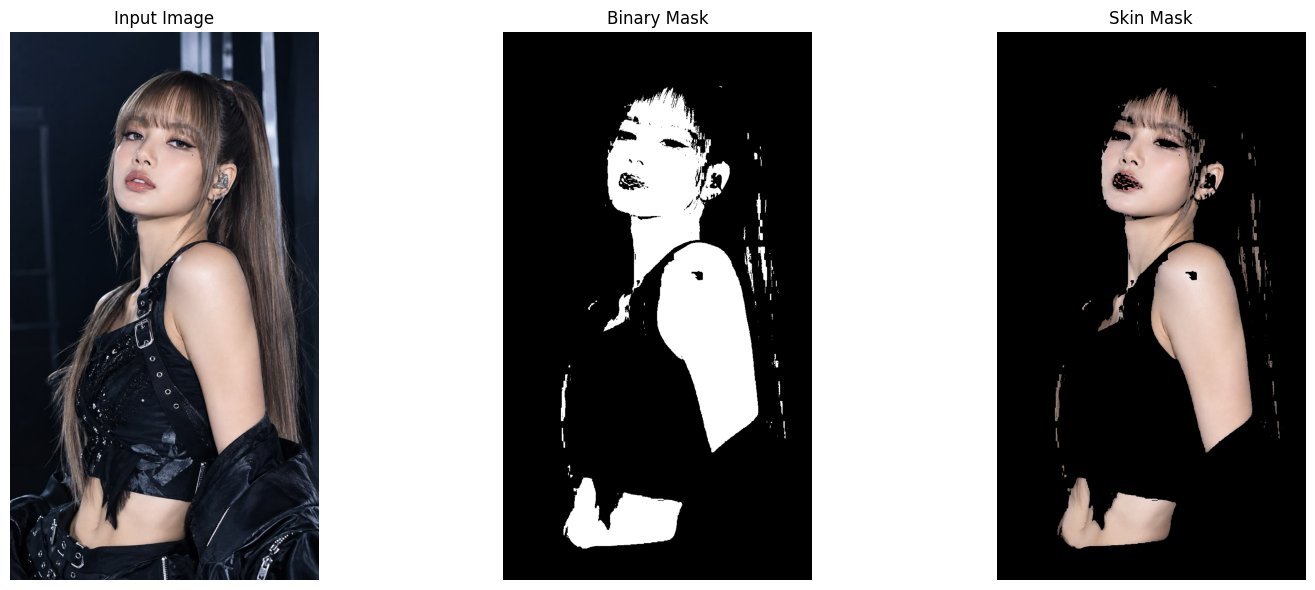

In [6]:
skin_result = np.zeros_like(img)
skin_result[skin_mask] = img[skin_mask]

binary_mask = skin_mask.astype(np.uint8) * 255

plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Input Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(binary_mask, cmap='gray')
plt.title('Binary Mask')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(skin_result, cv2.COLOR_BGR2RGB))
plt.title('Skin Mask')
plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
cv2.imwrite('/content/skin_detection_result.jpg', skin_result)
cv2.imwrite('/content/skin_mask.jpg', binary_mask)
print('Saved: skin_detection_result.jpg')
print('Saved: skin_mask.jpg')

files.download('/content/skin_detection_result.jpg')
files.download('/content/skin_mask.jpg')
print('Download Started.')

Saved: skin_detection_result.jpg
Saved: skin_mask.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download Started.
